# Linear Gaussian inverse problem: numerical and statistical audits

The posterior is analytic. SVD and augmented QR avoid explicitly forming a squared-condition normal-equations matrix. Their accuracy is compared to an 80-digit oracle for the actual rounded inputs. Calibration is tested separately under the joint prior-predictive distribution. This is established methodology, not a new inference algorithm.

In [1]:
import json
from pathlib import Path
report=json.loads(Path('benchmarks/results.json').read_text())
print('Predeclared gate:', report['success'])
print('SVD versus QR:', report['max_svd_qr_difference'])
for row in report['selected']:
    print(row['d'],row['method'],'median relative mean error',row['median_mean_relative_error'],'failures',row['failed'])

Predeclared gate: True
SVD versus QR: 5.405661746354819e-10
4 svd median relative mean error 3.002540359698137e-10 failures 0
4 augmented_qr median relative mean error 1.1185881368944058e-09 failures 0
4 normal_equations median relative mean error 0.09291957819256574 failures 0
12 svd median relative mean error 9.352638856144605e-10 failures 0
12 augmented_qr median relative mean error 6.012076283461579e-10 failures 0
12 normal_equations median relative mean error 0.1533080727767636 failures 0
32 svd median relative mean error 1.034907628594011e-09 failures 0
32 augmented_qr median relative mean error 5.696124974832968e-10 failures 0
32 normal_equations median relative mean error 0.15259381161134838 failures 0


In [2]:
for row in report['calibration']:
    print(row['scenario'], row['direction'], 'coverage=',row['coverage_95'], 'Wilson 95% interval=',(row['coverage_wilson_low'],row['coverage_wilson_high']))

correct strong coverage= 0.947 Wilson 95% interval= (0.9313253831625082, 0.9592534947514054)
correct weak coverage= 0.953 Wilson 95% interval= (0.9380600619184716, 0.9644728948936154)
noise_understated strong coverage= 0.145 Wilson 95% interval= (0.12453493622851891, 0.16818206229622523)
noise_understated weak coverage= 0.843 Wilson 95% interval= (0.8191441706597944, 0.8642306730191147)
prior_too_tight strong coverage= 0.945 Wilson 95% interval= (0.9290916123226243, 0.9575025726252315)
prior_too_tight weak coverage= 0.145 Wilson 95% interval= (0.12453493622851891, 0.16818206229622523)


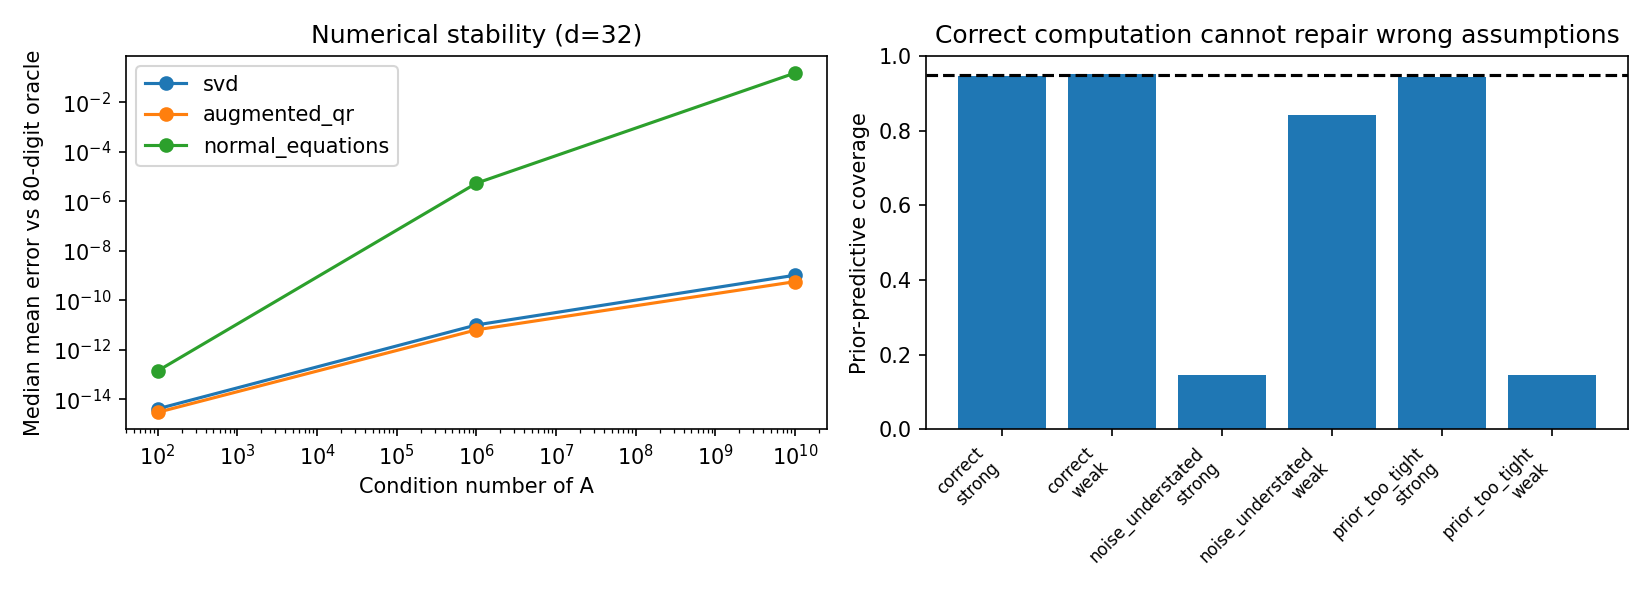

In [3]:
from IPython.display import Image,display
display(Image(filename='benchmarks/audit.png'))

In [4]:
import numpy as np
from src.posterior import posterior
a=np.diag([1.,.01,0.])
p=posterior(a,np.array([1.,.1,10.]),sigma=.1,tau=2.)
print('Mean:',p.mean)
print('Posterior variances:',np.diag(p.covariance))
assert abs(p.covariance[-1,-1]-4)<1e-12
print('The unobserved direction retains the prior variance.')

Mean: [0.99750623 0.38461538 0.        ]
Posterior variances: [0.00997506 3.84615385 4.        ]
The unobserved direction retains the prior variance.


## Conclusions and limits

Normal equations can lose accuracy despite small residuals. SVD is compared to a strong QR baseline: no universal superiority is asserted. A stable posterior still has poor coverage under an understated noise level or overly concentrated prior. Coverage here averages over draws of theta from the prior; it is not a fixed-theta frequentist guarantee. Dense finite-dimensional isotropic Gaussian assumptions exclude nonlinear operators, empirical financial calibration and model discrepancy inference.

## Desarrollo semanal: mecanismo, sensibilidad y controles

Las celdas nuevas recalculan experimentos específicos. Las salidas históricas anteriores se conservan como evidencia separada y no sustituyen esta ejecución.

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({'font.size':11,'axes.spines.top':False,'axes.spines.right':False})
SEED=20261018


### Identificabilidad por dirección singular
Con $A=USV^T$, la varianza posterior en la dirección j es $v_j=(s_j^2/\sigma^2+1/\tau^2)^{-1}$. Una dirección nula retiene $\tau^2$, aunque el residuo del ajuste sea pequeño. La contracción depende conjuntamente de singularidad y prior, no sólo del tamaño de los errores de resolución.

Se varía τ manteniendo el operador fijo. La referencia escalar espectral es independiente de la descomposición usada para resolver el posterior.

In [6]:
from src.posterior import posterior,spectral_variances
singular=np.array([1.,.1,.01,0.]);A=np.diag(singular);y=np.array([1.,.2,.03,0.]);sigma=.1
spectral_rows=[]
for tau in [.1,.3,1.,3.,10.]:
    result=posterior(A,y,sigma,tau)
    oracle=spectral_variances(singular,sigma,tau)
    assert np.allclose(np.diag(result.covariance),oracle,rtol=1e-10,atol=1e-14)
    assert abs(result.covariance[-1,-1]-tau*tau)<1e-10
    for index,s in enumerate(singular):spectral_rows.append(dict(tau=tau,singular=s,variance=result.covariance[index,index],prior_fraction=result.covariance[index,index]/tau**2))
spectral_table=pd.DataFrame(spectral_rows);display(spectral_table.round(6))

,tau,singular,variance,prior_fraction
0,0.1,1.00,0.005000,0.500000
1,0.1,0.10,0.009901,0.990099
2,0.1,0.01,0.009999,0.999900
3,0.1,0.00,0.010000,1.000000
4,0.3,1.00,0.009000,0.100000
5,0.3,0.10,0.082569,0.917431
6,0.3,0.01,0.089919,0.999101
7,0.3,0.00,0.090000,1.000000
8,1.0,1.00,0.009901,0.009901
9,1.0,0.10,0.500000,0.500000


### Cuánta información aporta cada dirección
La fracción varianza posterior/prior cercana a uno indica poca información de los datos en esa dirección. Comparar varianzas absolutas puede ocultar que un prior concentrado es el que produce un intervalo corto.

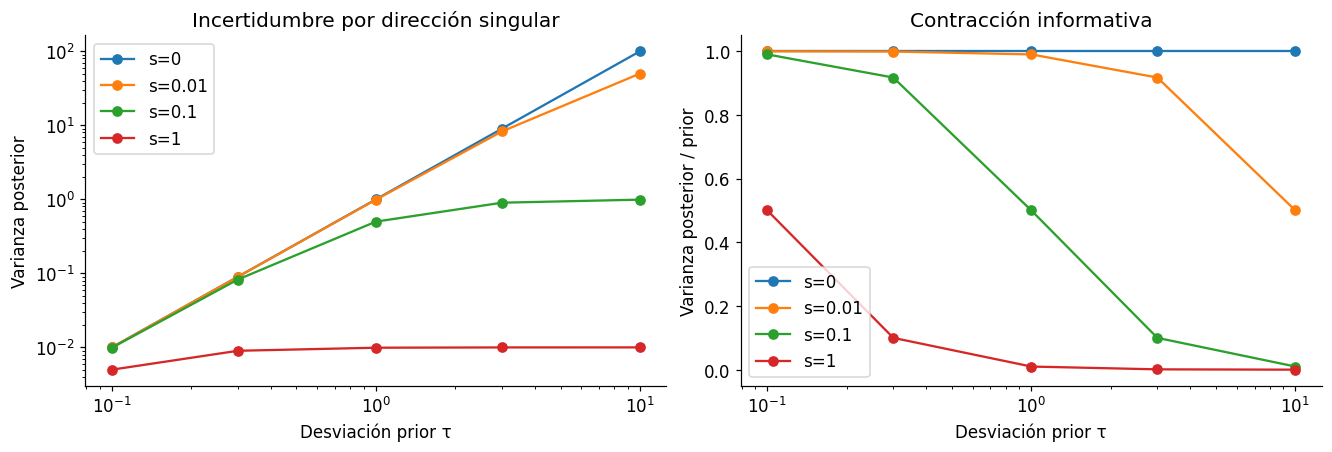

In [7]:
fig,axes=plt.subplots(1,2,figsize=(12,4),layout='constrained')
for s,group in spectral_table.groupby('singular'):
    axes[0].loglog(group.tau,group.variance,'o-',label=f's={s:g}')
    axes[1].semilogx(group.tau,group.prior_fraction,'o-',label=f's={s:g}')
axes[0].set(xlabel='Desviación prior τ',ylabel='Varianza posterior',title='Incertidumbre por dirección singular')
axes[1].set(xlabel='Desviación prior τ',ylabel='Varianza posterior / prior',title='Contracción informativa')
for ax in axes:ax.legend()
plt.show()

### Cobertura fija frente a promedio prior predictivo
La cobertura de un intervalo creíble puede ser 95% al promediar bajo el prior correcto y ser muy inferior para un parámetro fijo incompatible con ese prior. Usamos 400 réplicas independientes por escenario, con un operador de dos dimensiones y ruido conocido. Los intervalos de Wilson describen incertidumbre binomial de la cobertura Monte Carlo, no incertidumbre del parámetro θ.

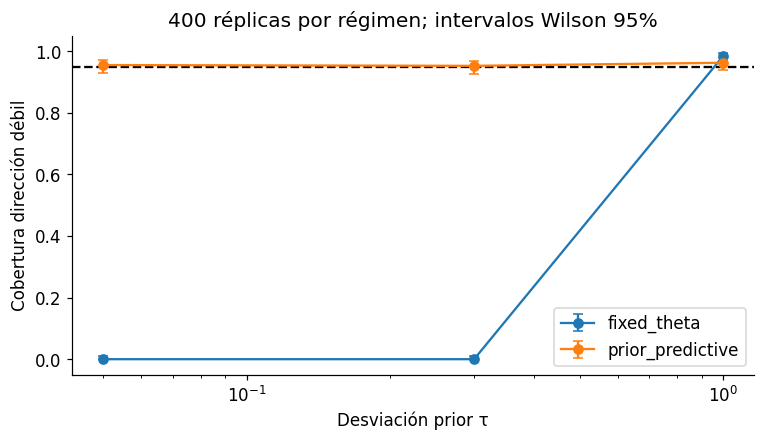

,tau,regime,coverage,wilson_low,wilson_high,mean_width
0,0.05,fixed_theta,0.0000,0.0000,0.0095,0.1959
1,0.05,prior_predictive,0.9550,0.9300,0.9713,0.1959
2,0.30,fixed_theta,0.0000,0.0000,0.0095,1.1630
3,0.30,prior_predictive,0.9525,0.9270,0.9694,1.1630
4,1.00,fixed_theta,0.9850,0.9677,0.9931,3.5061
5,1.00,prior_predictive,0.9625,0.9391,0.9771,3.5061


In [8]:
rng=np.random.default_rng(SEED);operator=np.diag([1.,.1]);sigma=.2
coverage_rows=[]
for tau in [.05,.3,1.]:
    for regime in ['fixed_theta','prior_predictive']:
        covered=[];widths=[]
        for replicate in range(400):
            theta=np.array([1.,1.]) if regime=='fixed_theta' else rng.normal(scale=tau,size=2)
            observation=operator@theta+rng.normal(scale=sigma,size=2)
            result=posterior(operator,observation,sigma,tau)
            sd=np.sqrt(np.diag(result.covariance))
            covered.append(abs(result.mean[1]-theta[1])<=1.95996398454*sd[1]);widths.append(2*1.95996398454*sd[1])
        rate=np.mean(covered);N=len(covered);z=1.95996398454
        center=(rate+z*z/(2*N))/(1+z*z/N)
        half=z*np.sqrt(rate*(1-rate)/N+z*z/(4*N*N))/(1+z*z/N)
        coverage_rows.append(dict(tau=tau,regime=regime,coverage=rate,wilson_low=center-half,wilson_high=center+half,mean_width=np.mean(widths)))
coverage_table=pd.DataFrame(coverage_rows);display(coverage_table.round(4))
assert coverage_table.coverage.between(0,1).all()
fig,ax=plt.subplots(figsize=(8,4))
for regime,group in coverage_table.groupby('regime'):
    ax.errorbar(group.tau,group.coverage,yerr=[group.coverage-group.wilson_low,group.wilson_high-group.coverage],fmt='o-',capsize=3,label=regime)
ax.axhline(.95,color='black',linestyle='--');ax.set(xscale='log',ylim=(-.05,1.05),xlabel='Desviación prior τ',ylabel='Cobertura dirección débil',title='400 réplicas por régimen; intervalos Wilson 95%')
ax.legend();plt.show()

### Interpretación
Se separan tres preguntas: si se resuelve bien el sistema, qué direcciones se identifican y si el modelo probabilístico produce intervalos útiles. Un error de álgebra pequeño no responde las dos últimas. El ejemplo de cobertura fija no contradice calibración bayesiana promedio bajo un prior correctamente especificado.